# LangGraph Practice

In this notebook, we will build a basic agent using the **LangGraph** framework. We will cover:
1.  Creating a basic agent.
2.  Using standard tools.
3.  Simulating an **MCP (Model Context Protocol)** tool.
4.  Observing the agent's execution steps.

We will use an **Azure OpenAI** deployment (`gpt-5.4-mini` by default).

## 1. Prerequisites and Installation
First, let's install the necessary libraries.

In [26]:
%pip install -qU langgraph langchain-core langchain-openai python-dotenv grandalf

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Setup Environment Variables
We need the Azure OpenAI credentials. Store them in a `.env` file (in this folder or any parent folder); if a value is missing, the cell below prompts for it.
```
AZURE_OPENAI_API_KEY=<your-key>
AZURE_OPENAI_ENDPOINT=https://<resource>.openai.azure.com/openai/v1/
AZURE_OPENAI_DEPLOYMENT=gpt-5.4-mini
```

In [27]:
import getpass
import os

from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))

if not os.environ.get("AZURE_OPENAI_API_KEY"):
    os.environ["AZURE_OPENAI_API_KEY"] = getpass.getpass("Enter your Azure OpenAI API key: ")
if not os.environ.get("AZURE_OPENAI_ENDPOINT"):
    os.environ["AZURE_OPENAI_ENDPOINT"] = input("Enter your Azure OpenAI endpoint (https://<resource>.openai.azure.com/): ")

# Accept either the resource URL or the full v1 base URL
AZURE_OPENAI_ENDPOINT = os.environ["AZURE_OPENAI_ENDPOINT"].rstrip("/").removesuffix("/openai/v1") + "/openai/v1/"
AZURE_OPENAI_DEPLOYMENT = os.environ.get("AZURE_OPENAI_DEPLOYMENT", "gpt-5.4-mini")
print(f"Using Azure OpenAI deployment: {AZURE_OPENAI_DEPLOYMENT}")

Using Azure OpenAI deployment: gpt-5.4-mini


### 2.1 Setup Observability (LangSmith)
To visualize the agent's steps, we will use LangSmith. You can sign up for a free account at [smith.langchain.com](https://smith.langchain.com/).

Tracing is enabled when `LANGSMITH_API_KEY` is set (in `.env` or via the prompt below; leave the prompt empty to skip tracing). If your LangSmith organization is hosted in the EU region ([eu.smith.langchain.com](https://eu.smith.langchain.com/)), also set `LANGSMITH_ENDPOINT=https://eu.api.smith.langchain.com`.

In [28]:
if not os.environ.get("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_API_KEY"] = getpass.getpass("Enter your LangSmith API key (leave empty to skip tracing): ")

os.environ["LANGSMITH_TRACING"] = "true" if os.environ["LANGSMITH_API_KEY"] else "false"
print(f"LangSmith tracing enabled: {os.environ['LANGSMITH_TRACING']}")

LangSmith tracing enabled: true


## 3. Initialize the Azure OpenAI Model
Azure OpenAI's v1 API is OpenAI-compatible, so we use `ChatOpenAI` with `base_url` pointing at the Azure endpoint and `model` set to the deployment name.

**Note:** GPT-5-family deployments are reasoning models that only support the default `temperature`, so we don't set it.

In [29]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model=AZURE_OPENAI_DEPLOYMENT,
    base_url=AZURE_OPENAI_ENDPOINT,
    api_key=os.environ["AZURE_OPENAI_API_KEY"],
)

## 4. Define a Basic Calculator Tool
We'll create a simple multiplication tool.

In [30]:
from langchain_core.tools import tool

@tool
def multiply(a: int, b: int) -> int:
    """Multiplies two integers."""
    return a * b

print(multiply.name)
print(multiply.description)
print(multiply.args)

multiply
Multiplies two integers.
{'a': {'title': 'A', 'type': 'integer'}, 'b': {'title': 'B', 'type': 'integer'}}


## 5. Define an MCP Tool (Mock Weather Service)
The **Model Context Protocol (MCP)** is a standard for connecting AI models to external data and tools.
Here, we will simulate an MCP tool that fetches weather data. In a real scenario, this would connect to an MCP server.

In [ ]:
@tool
def get_weather_mcp(city: str) -> str:
    """
    Fetches weather data for a given city.
    This tool simulates an MCP tool interaction.
    """

    mock_data = {
        "London": "Rainy, 15°C",
        "New York": "Sunny, 22°C",
        "Tokyo": "Cloudy, 18°C"
    }
    return mock_data.get(city, "Weather data not available for this city.")

tools = [multiply, get_weather_mcp]
llm_with_tools = llm.bind_tools(tools)

## 6. Define the Agent State
We need a state to hold the conversation history.

In [32]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

## 7. Create Nodes
We define the **Agent Node** (which calls the model) and the **Tool Node** (which executes tools).

In [33]:
from langgraph.prebuilt import ToolNode

def chatbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

tool_node = ToolNode(tools)

## 8. Build the LangGraph Workflow
We connect the nodes and define the logic.

In [34]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(State)

graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", tool_node)

graph_builder.add_edge(START, "chatbot")

def route_tools(state: State):
    if state["messages"][-1].tool_calls:
        return "tools"
    return END

graph_builder.add_conditional_edges("chatbot", route_tools, {"tools": "tools", END: END})
graph_builder.add_edge("tools", "chatbot")

graph = graph_builder.compile()

## 9. Visualize the Graph

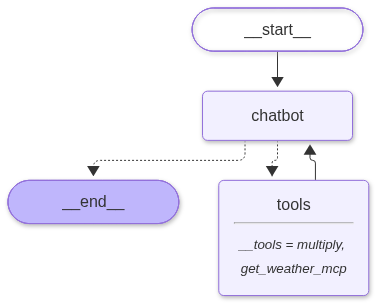

In [35]:
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print("Could not draw graph (requires graphviz/mermaid support).")
    graph.get_graph().print_ascii()

## 10. Run the Agent with Observability
We can now run the agent. LangGraph provides built-in observability by allowing us to stream the steps.

In [36]:
user_input = "What is 5 times 8? Also, what is the weather in London?"

events = graph.stream(
    {"messages": [("user", user_input)]},
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

What is 5 times 8? Also, what is the weather in London?
================================== Ai Message ==================================
Tool Calls:
  multiply (call_Bkf0e5EstIy7PJy2KT3f76O7)
 Call ID: call_Bkf0e5EstIy7PJy2KT3f76O7
  Args:
    a: 5
    b: 8
  get_weather_mcp (call_cXmHJuER30W3p9tvXkpFDzlG)
 Call ID: call_cXmHJuER30W3p9tvXkpFDzlG
  Args:
    city: London
================================= Tool Message =================================
Name: get_weather_mcp

Rainy, 15°C
================================== Ai Message ==================================

5 times 8 is 40.

The weather in London is Rainy, 15°C.


## 11. Observe the run in Langsmith

![LangSmith traces of my agent runs](langsmith_trace.png)

## 12. Challenge: Build a Travel Assistant

Now it's your turn! Apply what you've learned to build a **Travel Assistant Agent**.

**Requirements:**
1.  **Create a Tool**: `calculate_distance(origin: str, destination: str) -> int`. Return a mock distance (e.g., based on the length of the city names or just a random number).
2.  **Create an MCP Tool**: `get_hotel_recommendations_mcp(city: str) -> str`. Return a mock list of hotels for the given city.
3.  **Build the Graph**: Create a new `StateGraph` with a new agent node and tool node.
4.  **Run**: Ask the agent: *"I want to travel from New York to Paris. How far is it and can you recommend a hotel?"*
5.  **Observe**: Use the streaming output to verify the tools are called correctly.

In [38]:
# TODO: Implement your Travel Assistant here

# 1. Define tools
@tool
def calculate_distance(origin: str, destination: str) -> int:
    """Calculates the distance between two cities in km."""
    distances = {
        ("New York", "Paris"): 5837,
        ("London", "Paris"): 344,
        ("Tokyo", "Paris"): 9712,
    }
    return distances.get((origin, destination), (len(origin) + len(destination)) * 100)


@tool
def get_hotel_recommendations_mcp(city: str) -> str:
    """
    Fetches hotel recommendations for a city.
    This tool simulates an MCP tool interaction.
    """
    # In a real MCP implementation, this would make a request to an MCP server.
    mock_hotels = {
        "Paris": "Hotel Le Meurice, Hotel Plaza Athenee, Hotel Lutetia",
        "London": "The Savoy, The Ritz London",
        "New York": "The Plaza, The Standard High Line",
    }
    return mock_hotels.get(city, "No hotel data available for this city.")


# 2. Bind tools to LLM
travel_tools = [calculate_distance, get_hotel_recommendations_mcp]
llm_travel = llm.bind_tools(travel_tools)

# 3. Define Agent Node
def travel_agent(state: State):
    return {"messages": [llm_travel.invoke(state["messages"])]}

travel_tool_node = ToolNode(travel_tools)

# 4. Build Graph
travel_graph = StateGraph(State)
travel_graph.add_node("travel_agent", travel_agent)
travel_graph.add_node("tools", travel_tool_node)

travel_graph.add_edge(START, "travel_agent")
travel_graph.add_conditional_edges("travel_agent", route_tools, {"tools": "tools", END: END})
travel_graph.add_edge("tools", "travel_agent")

travel_app = travel_graph.compile()

# 5. Run and Observe
user_input = "I want to travel from New York to Paris. How far is it and can you recommend a hotel?"

events = travel_app.stream(
    {"messages": [("user", user_input)]},
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I want to travel from New York to Paris. How far is it and can you recommend a hotel?
================================== Ai Message ==================================
Tool Calls:
  calculate_distance (call_mIPyjOsZaI1b9rV12KSabGe5)
 Call ID: call_mIPyjOsZaI1b9rV12KSabGe5
  Args:
    origin: New York
    destination: Paris
  get_hotel_recommendations_mcp (call_AR6RmqJlZ7SaiHUANfrw3fGG)
 Call ID: call_AR6RmqJlZ7SaiHUANfrw3fGG
  Args:
    city: Paris
================================= Tool Message =================================
Name: get_hotel_recommendations_mcp

Hotel Le Meurice, Hotel Plaza Athenee, Hotel Lutetia
================================== Ai Message ==================================

The distance from New York to Paris is about **5,837 km**.

Recommended hotels in Paris:
- **Hotel Le Meurice**
- **Hotel Plaza Athenee**
- **Hotel Lutetia**

If you want, I can also help you narrow these down by 